# Install model and model-specific dependencies
Run from the terminal

## Load Starting Weights
The ProtiCelli example requires two sets of weights:
* **DiT weights** (`checkpoint/unet/`): the diffusion model that predicts the protein image. Training updates these weights.
* **VAE weights** (`vae/`): the autoencoder that converts images to and from the compact form the DiT works in. It is frozen during training and needed by every option below.

Download both to `~/reference/proticelli/` and point the model at the folders as required for each option.

Options for the DiT weights:

1. **Pretrained ProtiCelli** (used in this tutorial): the published weights from the Lundberg lab.
2. **Random weights**: point `checkpoint_dir` at an empty folder, and ProtiCelli starts from randomly initialized weights. The pretrained VAE is still required.
3. **Existing weights**: copy weights from the workspace bucket (for example, from an earlier fine-tuning run) to the persistent disk, and point `checkpoint_dir` at them.

Check: `checkpoint_ready()` should be True for options 1 and 3 and False for option 2. ProtiCelli falls back to random weights without warning if it cannot find `checkpoint/unet/`.

In [1]:
# Download ProtiCelli weights if not present
from pathlib import Path
from proticelli.model import Model
from proticelli.utils.download import checkpoint_ready, vae_ready

root = Path.home() / "reference" / "proticelli"
if not (checkpoint_ready(root) and vae_ready(root)):
    Model.download_checkpoints(dest_dir=root)
print("DiT weights found:", checkpoint_ready(root), "| VAE found:", vae_ready(root))

  100% · 6556.9 of 6556.9 MiB
  Validating and installing checkpoint…
  100% · 125.2 of 125.2 MiB
  Validating and installing vae…
ProtiCelli model assets are ready.
DiT weights found: True | VAE found: True


## Check the GPU
On AnVIL, the GPU is chosen when the cloud environment is created; if this cell reports CPU, recreate the environment with a GPU attached.

In [2]:
import torch

if torch.cuda.is_available():
    DEVICE = "cuda"
    print("CUDA GPU:", torch.cuda.get_device_name(0), f"({torch.cuda.get_device_properties(0).total_memory / 2**30:.0f} GiB)")
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
    DEVICE = "mps"
    print("Apple GPU (MPS)")
else:
    DEVICE = "cpu"
    print("No GPU found: training will be very slow. Fine for checking the steps run, not for real training.")
print("PyTorch", torch.__version__)

CUDA GPU: Tesla T4 (15 GiB)
PyTorch 2.8.0+cu128


# Training
Processing time estimates 

| Mode | Proteins | Cells per protein | Training cells (80%) | Epochs | Steps | Estimated time (T4) |
|---|---|---|---|---|---|---|
| smoke | 5 | 50 | 200 | 1 | 50 | about 5 minutes |
| quick | 5 | 100 | 400 | 2 | 200 | about 18 minutes |
| demo | 5 | 200 | 800 | 5 | 1,000 | about 1.5 hours |
| longer | 5 | 200 | 800 | 10 | 2,000 | about 3 hours |

Each step trains on a batch of 4 cells and took about 5.3 seconds on an AnVIL T4 GPU.  
Steps = training cells × epochs ÷ batch size.   
Time = steps × 5.3 seconds, plus a few minutes of setup.   
Measured once (2026-11-10, quick mode, 50 steps); treat these as estimates.

In [6]:
PROTEINS = ["DNMT3B", "MTERF3", "DFFA", "ERAL1", "DEAF1"]   # must be in the ProtiCelli vocabulary
RUN_MODE = "smoke"
MODES = {
    "smoke":  dict(cells_per_protein=50,  epochs=1),
    "quick":  dict(cells_per_protein=100, epochs=2),
    "demo":   dict(cells_per_protein=200, epochs=5),
    "longer": dict(cells_per_protein=200, epochs=10),
}
TEST_FRACTION = 0.2
BATCH_SIZE = 4
SEED = 1

from proticelli.model import Model

vocab = Model().protein_map   # reads only the vocabulary file; no weights are loaded
missing = [p for p in PROTEINS if p not in vocab]
assert not missing, f"Not in the ProtiCelli vocabulary: {missing}"

## Create the training/test manifest
Dataset manifest is one line per cell, identifies field-of-view and and associated image files.   
Split each protein in to training/test sets by field of view.  
Trim each protein into the number of cells specified in the run mode.   
Save as a table.

In [7]:
import os, sys, subprocess, tarfile
from pathlib import Path
import numpy as np, pandas as pd

DATASET = "KOLF-train_v1.0"
BUCKET = f"gs://fc-7533ae9b-e06e-4297-9bd5-a4dbc0895420/{DATASET}"   # challenge data, requester pays
DATA_DIR = Path.home() / "data" / DATASET
DATA_DIR.mkdir(parents=True, exist_ok=True)

def fetch(rel):
    dest = DATA_DIR / rel
    if not dest.exists():
        dest.parent.mkdir(parents=True, exist_ok=True)
        subprocess.run(["gcloud", "storage", "cp", f"--billing-project={os.environ['GOOGLE_PROJECT']}",
                        f"{BUCKET}/{rel}", str(dest)], check=True)
    return dest

manifest = pd.read_csv(fetch("kolf_train_manifest.csv.gz"), dtype=str, keep_default_na=False)
cells = manifest[manifest["gene_name"].isin(PROTEINS)].copy()

rng = np.random.default_rng(SEED)
mode = MODES[RUN_MODE]
parts = []
for gene, g in cells.groupby("gene_name"):
    fovs = g["fov_key"].unique()
    rng.shuffle(fovs)
    test_fovs = set(fovs[: max(1, round(len(fovs) * TEST_FRACTION))])
    g = g.assign(split=np.where(g["fov_key"].isin(test_fovs), "test", "train"))
    n_train = round(mode["cells_per_protein"] * (1 - TEST_FRACTION))
    n_test = mode["cells_per_protein"] - n_train
    for split, n in [("train", n_train), ("test", n_test)]:
        s = g[g["split"] == split]
        parts.append(s.sample(min(n, len(s)), random_state=SEED))
cells = pd.concat(parts)
cells.to_csv(DATA_DIR / f"cells_{RUN_MODE}_seed{SEED}.csv", index=False)
print(cells.groupby(["gene_name", "split"]).size().unstack())

Copying gs://fc-7533ae9b-e06e-4297-9bd5-a4dbc0895420/KOLF-train_v1.0/kolf_train_manifest.csv.gz to file:///home/jupyter/data/KOLF-train_v1.0/kolf_train_manifest.csv.gz
  
.

Average throughput: 201.3MiB/s


split      test  train
gene_name             
DEAF1        10     40
DFFA         10     40
DNMT3B       10     24
ERAL1        10     40
MTERF3       10     40


## Download Images
Cell images are stored as one archive per antibody. Download and unpack the archive for each chosen antibody. Later runs and other modes reuse the unpacked folders.

In [9]:
for antibody_id, tar_name in cells.drop_duplicates("antibody_id")[["antibody_id", "tar_file"]].values:
    if not (DATA_DIR / antibody_id).is_dir():
        tar_path = fetch(f"tars/{antibody_id[:5]}/{tar_name}")
        with tarfile.open(tar_path) as t:
            t.extractall(DATA_DIR, filter="data")
        tar_path.unlink()
        print("downloaded", antibody_id)

Copying gs://fc-7533ae9b-e06e-4297-9bd5-a4dbc0895420/KOLF-train_v1.0/tars/HPA03/HPA030302.tar to file:///home/jupyter/data/KOLF-train_v1.0/tars/HPA03/HPA030302.tar
  
....

Average throughput: 344.1MiB/s


downloaded HPA030302


Copying gs://fc-7533ae9b-e06e-4297-9bd5-a4dbc0895420/KOLF-train_v1.0/tars/HPA01/HPA019938.tar to file:///home/jupyter/data/KOLF-train_v1.0/tars/HPA01/HPA019938.tar
  
......

Average throughput: 223.7MiB/s


downloaded HPA019938


Copying gs://fc-7533ae9b-e06e-4297-9bd5-a4dbc0895420/KOLF-train_v1.0/tars/HPA00/HPA001803.tar to file:///home/jupyter/data/KOLF-train_v1.0/tars/HPA00/HPA001803.tar
  
....

Average throughput: 163.6MiB/s


downloaded HPA001803


Copying gs://fc-7533ae9b-e06e-4297-9bd5-a4dbc0895420/KOLF-train_v1.0/tars/HPA02/HPA021425.tar to file:///home/jupyter/data/KOLF-train_v1.0/tars/HPA02/HPA021425.tar
  
.....

Average throughput: 304.7MiB/s


downloaded HPA021425


Copying gs://fc-7533ae9b-e06e-4297-9bd5-a4dbc0895420/KOLF-train_v1.0/tars/HPA00/HPA007355.tar to file:///home/jupyter/data/KOLF-train_v1.0/tars/HPA00/HPA007355.tar
  
.....

Average throughput: 277.9MiB/s


downloaded HPA007355


## Model specific input format
Combine each training cell’s four images (microtubules, nucleus, ER and protein) into one file.   
Save formatted data in TRAIN_DIR.   
For this example, prediction and evaluation work from the challenge input format.

In [10]:
import tifffile
sys.path.insert(0, str(Path.home() / "blast-proticelli"))
from image_scaling import read_png
from proticelli.data import ChannelAssembler, ImageNormalizer

TRAIN_DIR = DATA_DIR / f"train_inputs_{RUN_MODE}_seed{SEED}"
TRAIN_DIR.mkdir(exist_ok=True)
assembler, normalizer = ChannelAssembler(has_protein=True), ImageNormalizer(bit_depth=8)

train = cells[cells["split"] == "train"]
for _, row in train.iterrows():
    out = TRAIN_DIR / f"{row['image_key']}.tiff"
    if not out.exists():
        raw = assembler.transform({ch: read_png(DATA_DIR / row[f"{ch}_path"])
                                   for ch in ("microtubules", "nucleus", "er", "protein")})
        tifffile.imwrite(out, normalizer.transform(raw).astype(np.float32), compression="zlib")

TRAIN_FILES = [f"{k}.tiff" for k in train["image_key"]]
TRAIN_PROTEINS = train["gene_name"].tolist()
print(f"{len(TRAIN_FILES)} training inputs in {TRAIN_DIR}")

184 training inputs in /home/jupyter/data/KOLF-train_v1.0/train_inputs_smoke_seed1


# Train
Train the model with ProtiCelli’s fit(). Select the starting weights as described in step 1. At each step, a batch of protein images is corrupted with noise of random strength, and the model learns to recover them from the three reference images and the protein name. The plot shows each step’s loss and a running average. A falling average means the model is fitting the training cells. Whether it predicts held-out cells better is checked in the next steps.

The config attributes {'decay': 0.9995, 'inv_gamma': 1.0, 'min_decay': 0.0, 'optimization_step': 1000000, 'power': 0.75, 'update_after_step': 0, 'use_ema_warmup': True} were passed to DiTTransformer2DModel, but are not expected and will be ignored. Please verify your config.json configuration file.


184 cells, 46 steps, about 4 minutes on a T4
Fine-tuning: 184 images, 1 epochs, 46 steps, batch_size=4


Epoch 0:   0%|          | 0/46 [00:00<?, ?it/s]

Epoch 0: avg_loss=0.161709
Fine-tuning complete. Model saved to /home/jupyter/runs/KOLF-train_v1.0_smoke_seed1
Training took 4.3 minutes; weights in /home/jupyter/runs/KOLF-train_v1.0_smoke_seed1/unet_ema


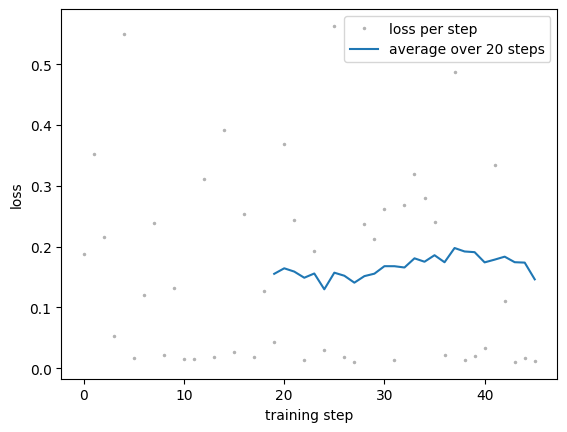

In [12]:
import math, time, torch
import matplotlib.pyplot as plt
from proticelli import Model
import proticelli._training as proticelli_training
from tqdm.auto import tqdm as original_tqdm

WEIGHTS = Path.home() / "reference" / "proticelli"   # where the starting weights were downloaded
CHECKPOINT_DIR = WEIGHTS / "checkpoint"   # pretrained; for random weights, point at an empty folder
OUT_DIR = Path.home() / "runs" / f"{DATASET}_{RUN_MODE}_seed{SEED}"
LEARNING_RATE = 1e-4
steps = mode["epochs"] * math.ceil(len(TRAIN_FILES) / BATCH_SIZE)
print(f"{len(TRAIN_FILES)} cells, {steps} steps, about {steps * 5.3 / 60:.0f} minutes on a T4")

# fit() shows each step's loss in its progress bar; record it there for the plot
losses = []
class RecordLoss(original_tqdm):
    def set_postfix(self, *args, **kwargs):
        if "loss" in kwargs:
            losses.append(float(kwargs["loss"]))
        return super().set_postfix(*args, **kwargs)
proticelli_training.tqdm = RecordLoss

torch.manual_seed(SEED)
model = Model(checkpoint_dir=CHECKPOINT_DIR, vae_dir=WEIGHTS / "vae")
started = time.perf_counter()
model.fit(
    image_dir=TRAIN_DIR, image_files=TRAIN_FILES, protein_names=TRAIN_PROTEINS,
    output_dir=str(OUT_DIR), num_epochs=mode["epochs"], batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE,
    lr_warmup_steps=max(1, steps // 10),   # fit()'s default of 500 would outlast a short run
    save_model_epochs=10,
    checkpointing_steps=10**9,             # no intermediate checkpoints (1.8 GB each)
)
print(f"Training took {(time.perf_counter() - started) / 60:.1f} minutes; weights in {OUT_DIR / 'unet_ema'}")

window = min(20, len(losses))
plt.plot(losses, ".", color="0.7", markersize=3, label="loss per step")
plt.plot(range(window - 1, len(losses)), np.convolve(losses, np.ones(window) / window, "valid"), label=f"average over {window} steps")
plt.xlabel("training step"); plt.ylabel("loss"); plt.legend(); plt.show()

# Package the trained weights files
Save the trained weights as one file in the model-specific format.   
In this example: the trained model (checkpoint/unet) and the image encoder it works with (vae, unchanged by training).   
The file goes on the persistent disk. The submission tutorial adds the files the example model needs to identify proteins from their sequence and turns this into a complete submission.   
Files can be saved to the WORKSPACE_BUCKET using `gcloud storage`.

In [13]:
import shutil, subprocess

WEIGHTS_FILES = Path.home() / "weights"
WEIGHTS_FILES.mkdir(exist_ok=True)
TRAINED_ZIP = WEIGHTS_FILES / f"trained_proticelli_{DATASET}_{RUN_MODE}_seed{SEED}.zip"

# The layout ProtiCelli loads (fit() saved the trained weights as unet_ema)
shutil.copytree(OUT_DIR / "unet_ema", OUT_DIR / "checkpoint" / "unet", dirs_exist_ok=True)

TRAINED_ZIP.unlink(missing_ok=True)      # always rebuild from the latest training run
subprocess.run(["zip", "-r", "-q", str(TRAINED_ZIP), "checkpoint/unet"], cwd=OUT_DIR, check=True)
subprocess.run(["zip", "-r", "-q", str(TRAINED_ZIP), "vae"], cwd=WEIGHTS, check=True)
cells.to_csv(OUT_DIR / "cells.csv", index=False)     # which cells trained these weights, and which were held out
print(f"{TRAINED_ZIP} ({TRAINED_ZIP.stat().st_size / 2**30:.1f} GiB)")

/home/jupyter/weights/trained_proticelli_KOLF-train_v1.0_smoke_seed1.zip (1.7 GiB)


In [ ]:
del model
torch.cuda.empty_cache()     # release the GPU for the prediction notebook